In [1]:
%load_ext autoreload
%autoreload 2
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from src.config import *
from src.utils import *
from src.experiments import run_experiment, show, augmented_cv

In [2]:
train = pd.read_csv(MULTI_FEATURES_TRAIN_CSV)
aug = pd.read_csv(MULTI_FEATURES_AUG_CSV)
feature_cols = [c for c in train.columns if c not in ("filename", "label")]

print("Augmented images per class:", aug["label"].map(MULTI_CLASS_NAMES).value_counts().to_dict())
print("All sources are training images:", aug["source_filename"].isin(train["filename"]).all())
print("Copies per source:", aug.groupby("source_filename").size().unique())
total = train["label"].value_counts().add(aug["label"].value_counts(), fill_value=0).astype(int)
print("Training images per class with augmentation:", {MULTI_CLASS_NAMES[k]: v for k, v in total.items()})

Augmented images per class: {'scc': 1504}
All sources are training images: True
Copies per source: [4]
Training images per class with augmentation: {'mel': 2713, 'bcc': 1993, 'scc': 1880}


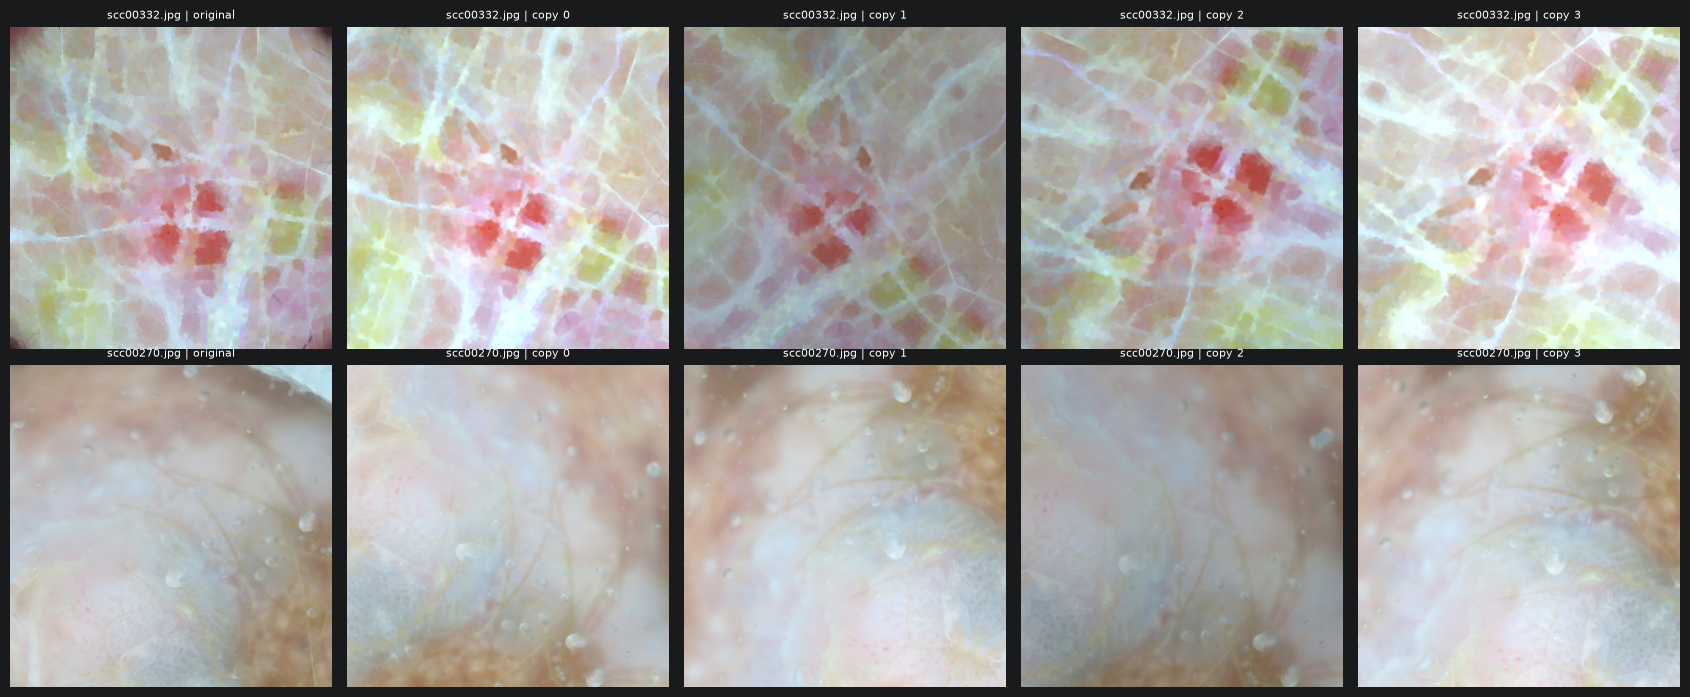

In [3]:
def load_aug(name, label):
    img = cv2.imread(str(MULTI_AUG_DIR / MULTI_CLASS_FOLDERS[label] / name))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

copies = aug.groupby("source_filename")["filename"].apply(list)
sources = copies.sample(2, random_state=np.random.randint(1000)).index

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for row, src in zip(axes, sources):
    imgs = [load_preprocessed(src, 2, MULTI_PREPROC_TRAIN_DIR, MULTI_CLASS_FOLDERS)]
    imgs += [load_aug(name, 2) for name in copies[src]]
    for ax, img, title in zip(row, imgs, ["original"] + [f"copy {k}" for k in range(4)]):
        ax.imshow(img); ax.set_title(f"{src} | {title}", fontsize=8); ax.axis("off")
plt.tight_layout()
plt.show()

Median distance copy -> its original:  12.4
Median distance between two scc images: 16.5


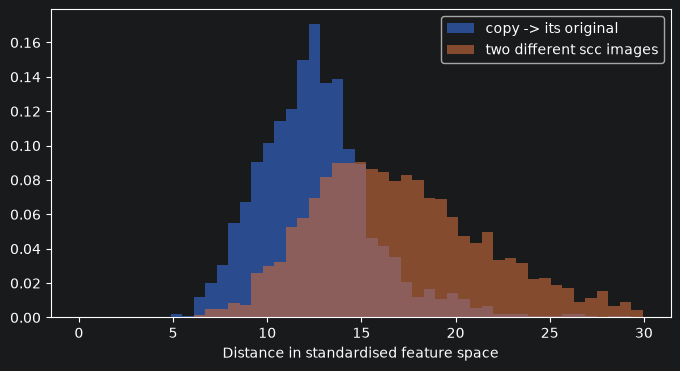

In [4]:
scaler = StandardScaler().fit(train[feature_cols])          # only for this check, not used by the models
Z_orig = pd.DataFrame(scaler.transform(train[feature_cols]), index=train["filename"])
Z_aug = scaler.transform(aug[feature_cols])

# distance of each copy to its own original
d_copy = np.linalg.norm(Z_aug - Z_orig.loc[aug["source_filename"]].values, axis=1)

# distance between two different real scc images
Z_scc = Z_orig[train["label"].values == 2].values
rng = np.random.default_rng(RANDOM_STATE)
i, j = rng.integers(0, len(Z_scc), (2, 3000))
d_pairs = np.linalg.norm(Z_scc[i[i != j]] - Z_scc[j[i != j]], axis=1)

print(f"Median distance copy -> its original:  {np.median(d_copy):.1f}")
print(f"Median distance between two scc images: {np.median(d_pairs):.1f}")

bins = np.linspace(0, np.percentile(d_pairs, 99), 50)
plt.figure(figsize=(8, 4))
plt.hist(d_copy, bins=bins, alpha=0.6, density=True, label="copy -> its original")
plt.hist(d_pairs, bins=bins, alpha=0.6, density=True, label="two different scc images")
plt.xlabel("Distance in standardised feature space")
plt.legend()
plt.show()

In [5]:
X_all = np.vstack([train[feature_cols].values, aug[feature_cols].values])
y_all = np.concatenate([train["label"].values, aug["label"].values])
splits = augmented_cv(train["filename"], aug["source_filename"], y_all)

for k, (tr, te) in enumerate(splits):
    print(f"fold {k}: train {len(tr)} (scc {np.sum(y_all[tr] == 2)}) | test {len(te)} originals (scc {np.sum(y_all[te] == 2)})")

fold 0: train 5269 (scc 1505) | test 1017 originals (scc 75)
fold 1: train 5265 (scc 1500) | test 1017 originals (scc 76)
fold 2: train 5270 (scc 1505) | test 1016 originals (scc 75)
fold 3: train 5270 (scc 1505) | test 1016 originals (scc 75)
fold 4: train 5270 (scc 1505) | test 1016 originals (scc 75)


In [ ]:
table_m2, fitted_m2 = run_experiment("M2 augmentation", X_all, y_all, task="multiclass", cv=splits)
show(table_m2, task="multiclass")

[M2 augmentation] LogReg: kappa = 0.620
[M2 augmentation] Random Forest: kappa = 0.633
[M2 augmentation] HistGradBoost: kappa = 0.683
[M2 augmentation] SVM (RBF): kappa = 0.703
[M2 augmentation] XGBoost: kappa = 0.691


In [ ]:
table_m3, fitted_m3 = run_experiment("M3 augmentation + weights", X_all, y_all, task="multiclass",
                                     weighted=True, cv=splits)
show(table_m3, task="multiclass")

In [ ]:
baseline = pd.read_csv(RESULTS_DIR / "multi_exp_baseline.csv")
table_aug = pd.concat([table_m2, table_m3], ignore_index=True)
table_aug.to_csv(RESULTS_DIR / "multi_exp_augmentation.csv", index=False)

all_m = pd.concat([baseline, table_aug], ignore_index=True)
display(show(all_m.sort_values("kappa", ascending=False), task="multiclass"))

best = all_m.loc[all_m["kappa"].idxmax()]
print(f"Best by CV kappa: {best['model']} ({best['experiment']}) - kappa {best['kappa']:.3f}")